# Receptive-field orientation, per task phase → `rf_orientation_stimulus.pdf`, `rf_orientation_delay.pdf`

[`../figure_3/model_comparison/rf_orientation.ipynb`](../figure_3/model_comparison/rf_orientation.ipynb)'s
figure, drawn once on the stimulus-period firing rate and once on the delay-period rate: where a
neuron's fitted 2-object phase sits relative to its own 1-object receptive field, over every
bootstrap. Rows are the two models, columns the two monkeys.

Each phase is a **refit**, not a subset: every model is fit to the firing rate over the **stimulus** period (0–1000 ms after stimulus onset, objects on screen) or the **delay** period (1000–2000 ms, objects gone) instead of the 2-s stimulus + delay window the main figure uses. The population is not re-selected: the shared 2-object modulation criterion is computed once on the 2-s window and applied first, so both phases are drawn over the same neurons as the main figure. The caches are built by `build_cache.py`; see `common.py` for how the window is switched. The 1-object receptive field each 2-object phase is measured against is fit in the
same window as it.

The shared 2-object modulation criterion is applied first, over the whole population, exactly as
in the main text. The **phase-determinacy** cut then runs *within* each task phase and is
BH-corrected across its neurons, so the contributing counts are genuinely that phase's own.


In [1]:
import matplotlib.pyplot as plt

import common
common.set_style()
import stats_lib as sl

FIGSIZE = (5.7, 4.1)
OUTPUT = 'rf_orientation_{group}.pdf'

# ── These must match ../figure_3/model_comparison/rf_orientation.ipynb ─────────
N_BINS = 40
NULL_LINE = False         # the horizontal rule at 1/N_BINS — the density a uniform
                          #   distribution would have. Off, as in the main-text notebook;
                          #   `plot_phase_histograms` defaults it on for historical reasons.
PHASE_FDR_Q = sl.PHASE_FDR_Q        # determinacy: BH within each task phase

# The uniformity tests draw their null rather than assuming an asymptotic form, so MC_DRAWS
# sets both the runtime and the floor on a reportable p: 1 / (MC_DRAWS + 1).
MC_DRAWS = 10000
MC_SEED = 0

# The population criterion, on as in the main text.
APPLY_MODULATION_CRITERION = True

# ── The tuning insets, matched to ../figure_3/model_comparison/rf_orientation.ipynb ──
# Drawn by `stats_lib.add_shift_insets`, the same function that notebook calls, so the
# supplement's insets cannot drift from the main text's.
INSET_SHIFTS_DEG = (-90, 0, 90, 180)   # where the insets sit on the x axis
INSET_RF_DEG = 90.0       # the 1-object receptive field every inset is measured against
INSET_SEP_DEG = 90.0      # inter-object angle of the chords inside each inset
INSET_N_ORIENT = 4        # chords per ring — four at 90 deg apart make the square v1 draws
INSET_SIZE_IN = 0.55      # side of an inset, in INCHES (they are square)
INSET_Y = 1.02            # bottom edge, in panel heights above the axis
INSET_TITLE_PAD = 6       # height of the column titles, in points above the axes
INSET_RADIUS = 0.38       # chord endpoints, in axes fractions from the inset's centre
INSET_ANNULUS_R = 0.44    # the 1-object annulus ...
INSET_ANNULUS_W = 0.06    # ... and its band width
INSET_LINEWIDTH = 2.0
ROW_HSPACE = 0.3          # vertical whitespace between the two model rows, as a fraction of
                          # axes height; opened before anything is placed, so the lower row's
                          # insets do not land inside the upper row's histogram
INSET_CONNECTOR_COLOR = '0.75'   # the line tying an inset to its x value: a pointer, not a
INSET_CONNECTOR_LW = 0.9         # datum, so it must never compete with the bars


In [2]:
groups = []
for phase in common.PHASES:
    common.use_phase(phase, verbose=True)
    units, phases = common.phase_fit(phase, apply_modulation=APPLY_MODULATION_CRITERION)
    groups.append((phase, units, phases))

phase: stimulus (0-1000 ms, `stimulus_fr`, 1 s)
2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
phase: delay (1000-2000 ms, `delay_fr`, 1 s)
2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons


Phase relative to the 1-object receptive field (all bootstraps):
  Monkey P —   Retinotopic: 592/998 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey P —   Relational: 607/998 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Retinotopic: 145/341 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Relational: 154/341 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)


saved rf_orientation_stimulus.pdf


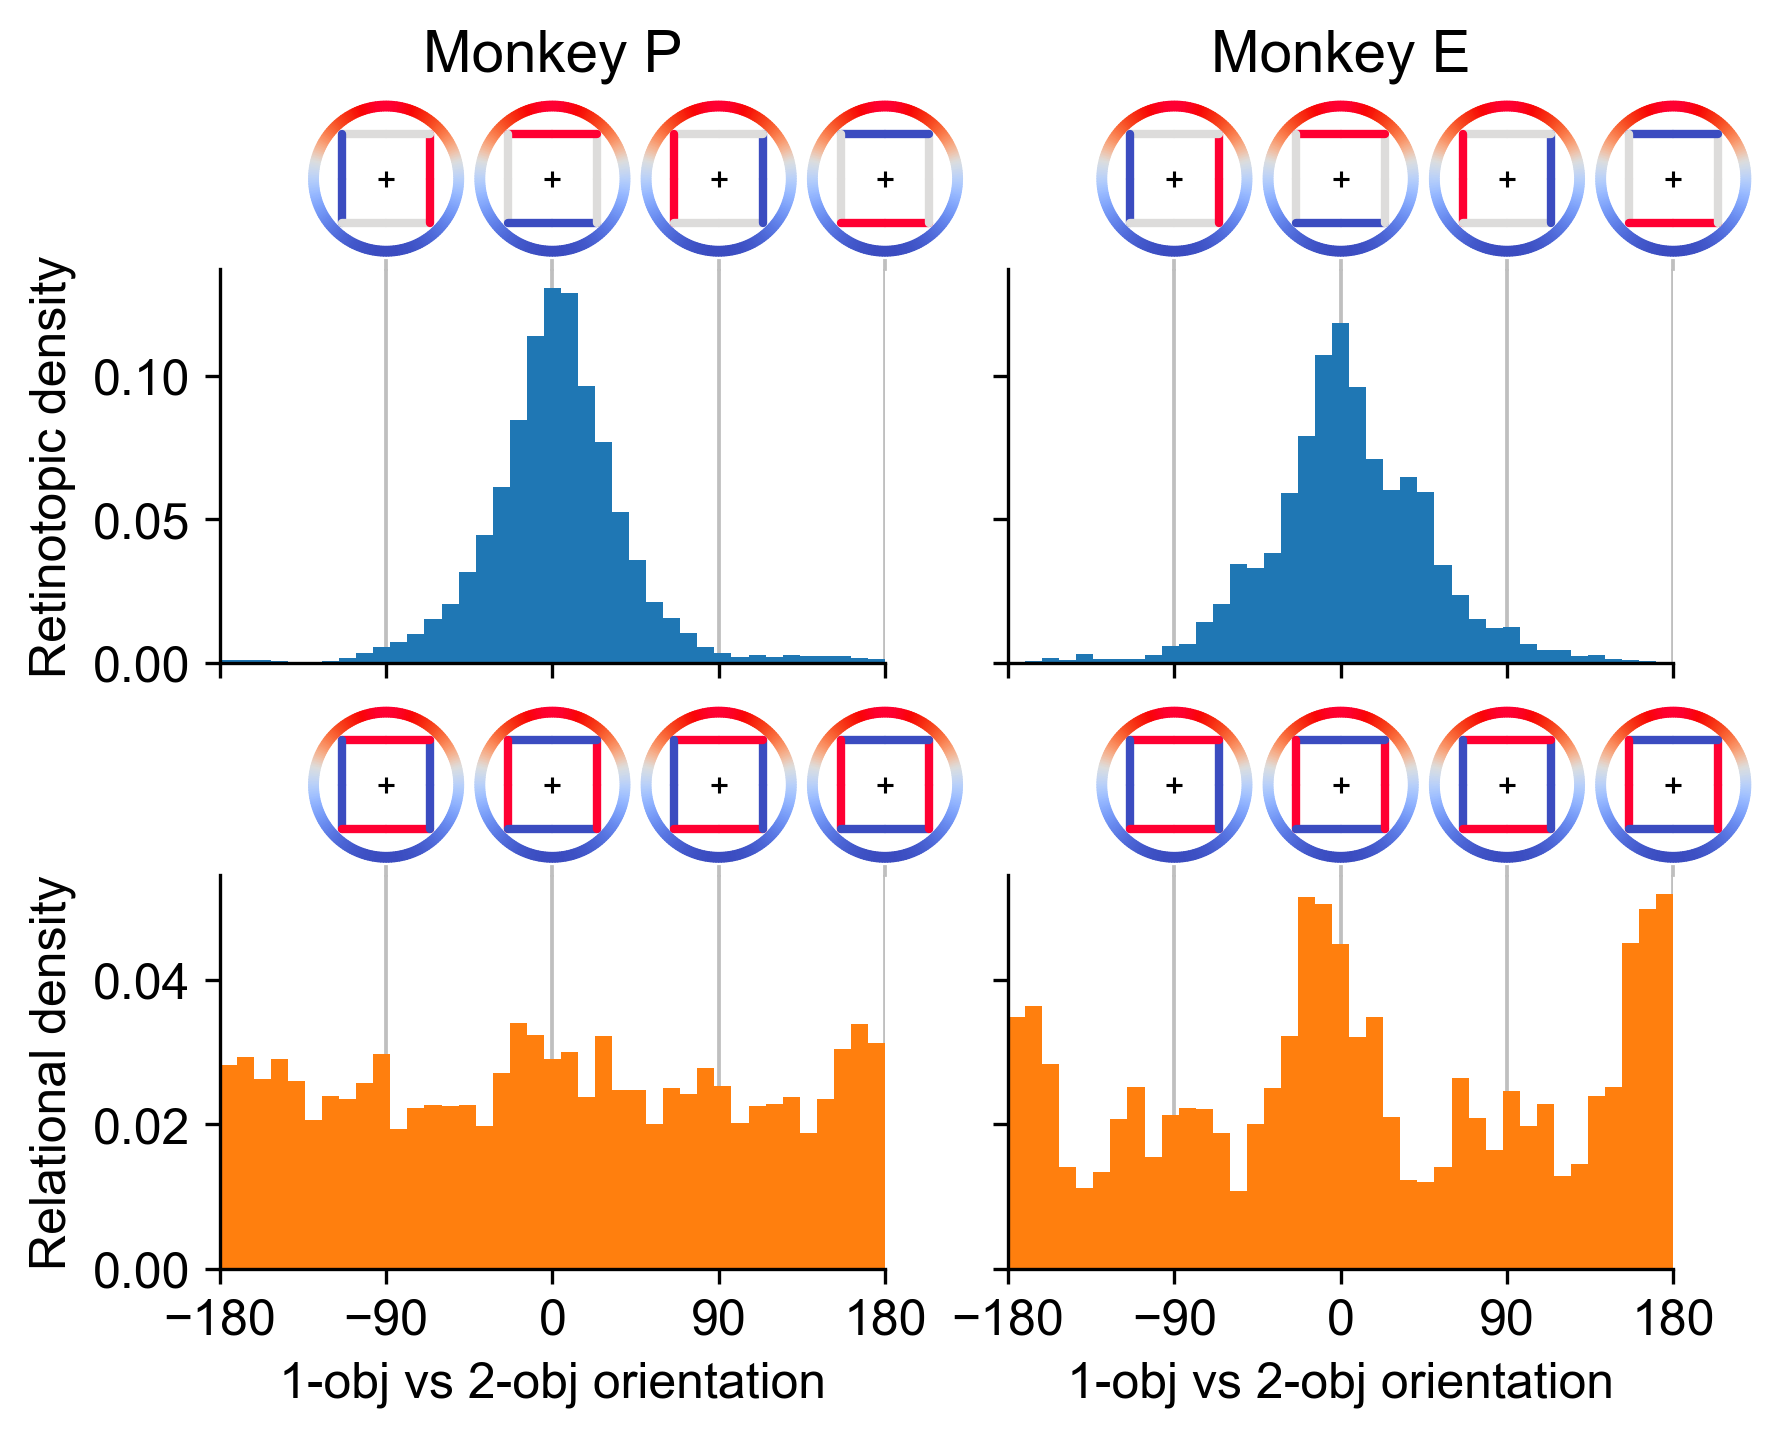

Phase relative to the 1-object receptive field (all bootstraps):
  Monkey P —   Retinotopic: 501/998 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey P —   Relational: 548/998 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Retinotopic: 114/341 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E — 

  Relational: 112/341 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)


saved rf_orientation_delay.pdf


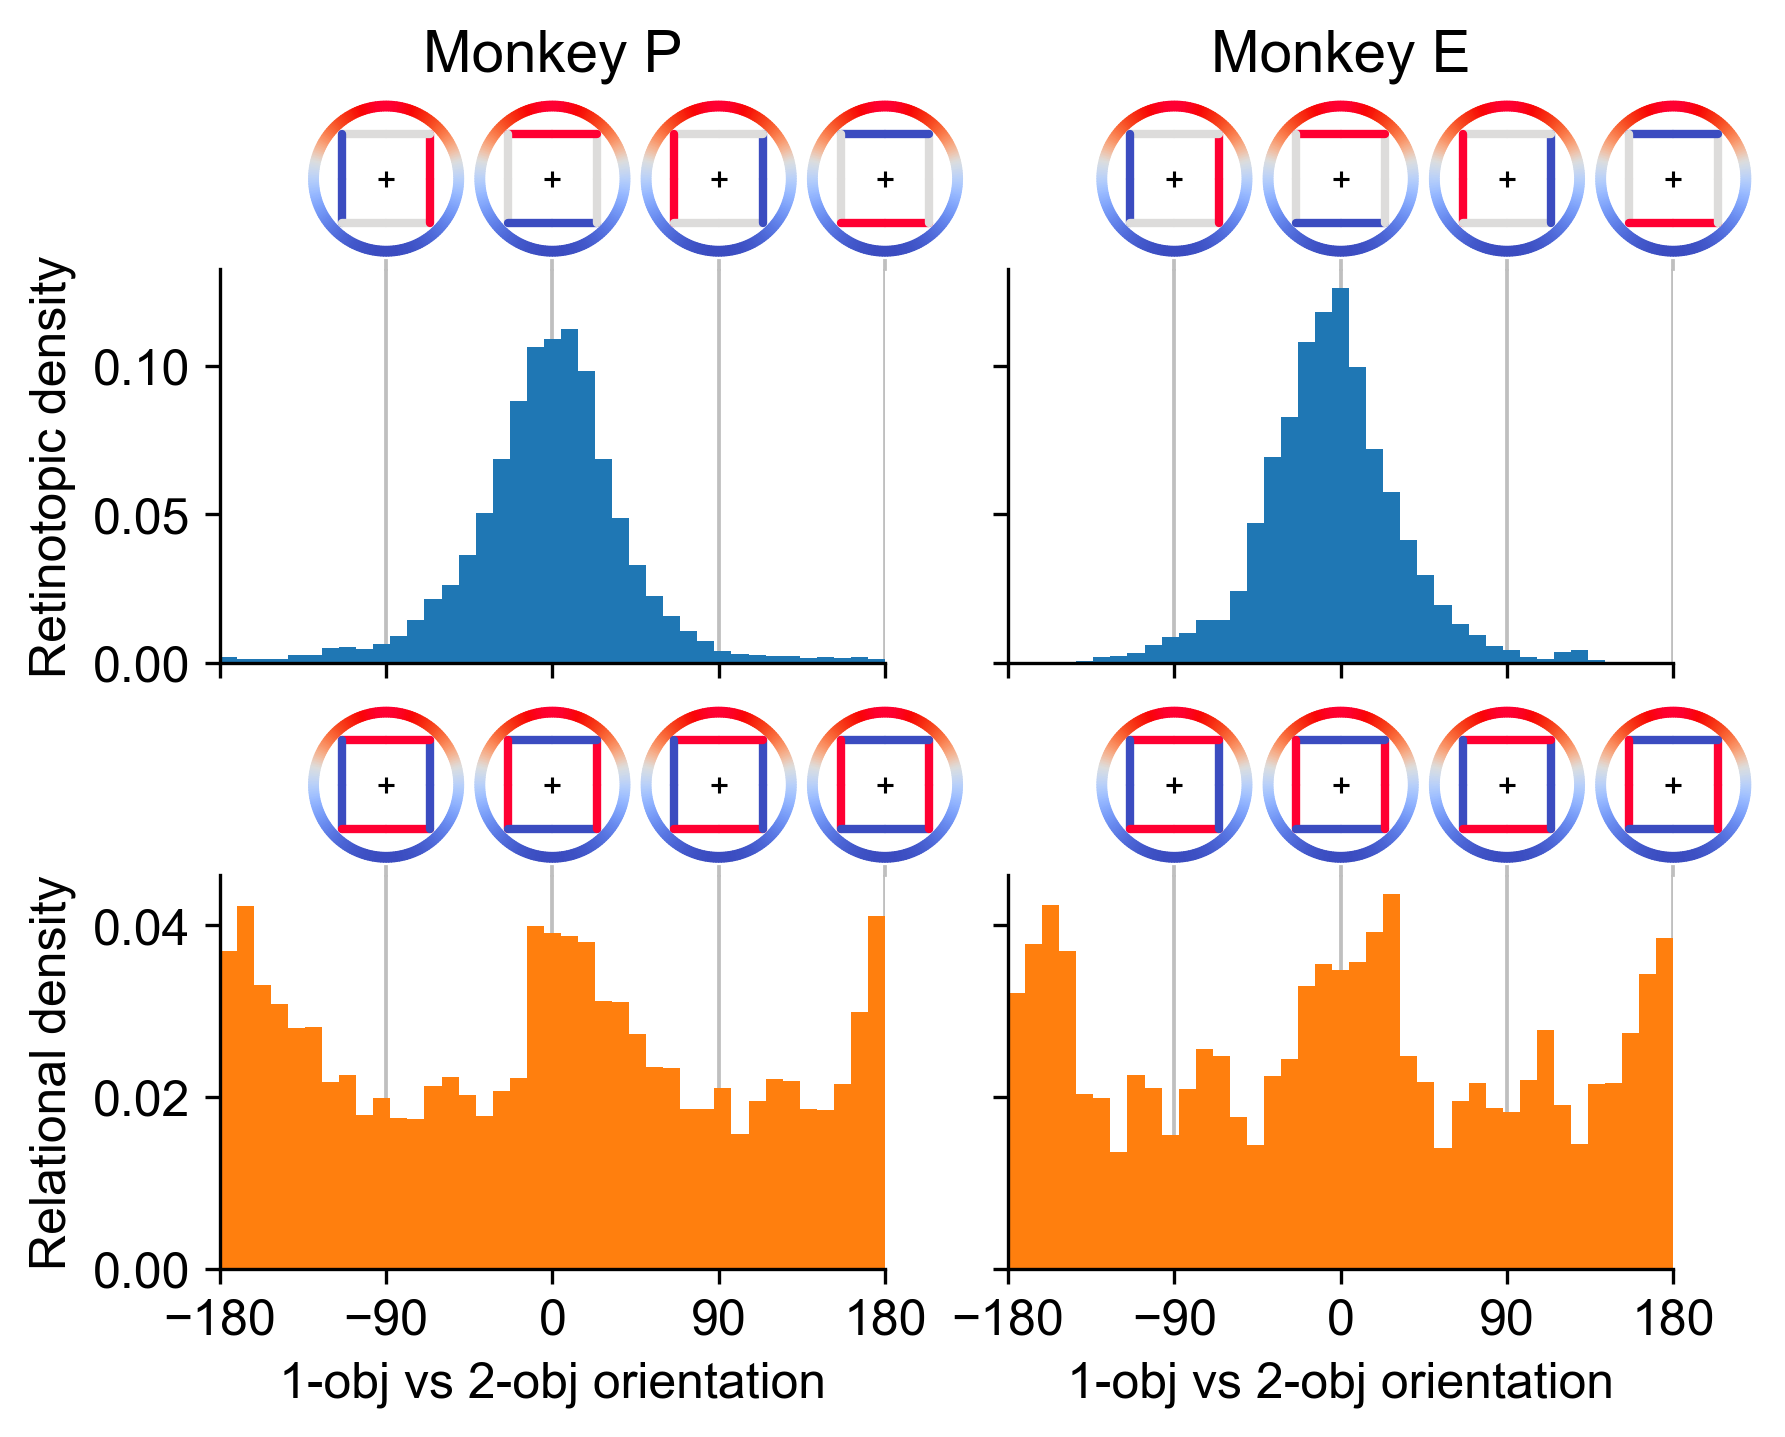

In [3]:
for group, group_units, phases in groups:
    fig, axes = sl.plot_phase_histograms(
        group_units, phases, n_bins=N_BINS, figsize=FIGSIZE, share_y='row', q=PHASE_FDR_Q,
        null_line=NULL_LINE)
    sl.add_shift_insets(fig, axes, sl.PHASE_MODELS, shifts_deg=INSET_SHIFTS_DEG,
                        rf_deg=INSET_RF_DEG, size_in=INSET_SIZE_IN, y=INSET_Y,
                        title_pad=INSET_TITLE_PAD, sep_deg=INSET_SEP_DEG,
                        n_orientations=INSET_N_ORIENT, radius=INSET_RADIUS,
                        annulus_radius=INSET_ANNULUS_R, annulus_width=INSET_ANNULUS_W,
                        linewidth=INSET_LINEWIDTH, hspace=ROW_HSPACE,
                        connector_color=INSET_CONNECTOR_COLOR,
                        connector_lw=INSET_CONNECTOR_LW)
    common.save(fig, OUTPUT.format(group=group))
    plt.show()

## What the criterion costs, and whether any of it is distinguishable from uniform

Both tables are the main-text notebook's, computed per task phase. The uniformity tests are given
**one value per neuron** from the point estimates — not the bootstrap draws the histogram plots,
which are resamples of the same neuron — and each row is tested on its own circle: 360° for the
retinotopic shift, which is a direction, 180° for the relational one, which is an axis. Testing
the relational row as a direction returns `R = 0.0000` for any data whatsoever, because the
plotted values come in pairs 180° apart.


In [4]:
import pandas as pd

for group, group_units, _ in groups:
    print(f'\n=== {group} ===')
    display(sl.exclusion_report(group_units, q=PHASE_FDR_Q))
    display(sl.uniformity_report(group_units, q=PHASE_FDR_Q, n_mc=MC_DRAWS, seed=MC_SEED))


=== stimulus ===


,model,n,determinate_2obj,determinate_1obj,enough_1obj_trials,all_criteria
0,Retinotopic,1339,1030,906,1244,737
1,Relational,1339,1129,906,1244,760


,subject,model,period_deg,n_neurons,mean_shift_deg,resultant,rayleigh_p,kuiper_p
0,Monkey P,Retinotopic,360.0,592,1.7,0.831,0.000100,0.000100
1,Monkey P,Relational,180.0,607,6.6,0.069,0.054595,0.038196
2,Monkey E,Retinotopic,360.0,145,4.3,0.780,0.000100,0.000100
3,Monkey E,Relational,180.0,154,170.0,0.236,0.000200,0.000200



=== delay ===


,model,n,determinate_2obj,determinate_1obj,enough_1obj_trials,all_criteria
0,Retinotopic,1339,919,779,1244,615
1,Relational,1339,1087,779,1244,660


,subject,model,period_deg,n_neurons,mean_shift_deg,resultant,rayleigh_p,kuiper_p
0,Monkey P,Retinotopic,360.0,501,358.5,0.795,0.000100,0.000100
1,Monkey P,Relational,180.0,548,13.6,0.184,0.000100,0.000100
2,Monkey E,Retinotopic,360.0,114,354.7,0.837,0.000100,0.000100
3,Monkey E,Relational,180.0,112,7.1,0.179,0.026397,0.025797
